# HW4: Stock prediction and trading strategy
**Pierre-Francois Pinelli**

1. Data: one row per stock and month-end, 18 characteristics, 90-day return
2. Model: elastic net on ranked characteristics, settings chosen on development data (2012-2015)
3. Strategy choice on development data
4. Backtester checks
5. Final test, Apr 2016 - Sep 2026, against $1M in the S&P 500 total return index

Code: `hw4_data.py` (data, adapted from the course `course_data.py`), `hw4_model.py` (model),
`hw4_backtest.py` (my backtester), `test_backtest.py` (hand-checked cases). Findings: `README.md`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import hw4_backtest as bt
import hw4_data as data
import hw4_model as model

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.4f}".format)
DB = Path(os.environ.get("HW4_DB", data.DB))
OUT = Path("outputs")  # cache folder, not on git

## 1. Data

One row per stock and month-end session (`date`, the signal). The characteristics use only
information known at that close. The trade is at the **next session's close** (`entry_date`), and
`target` is the return from that close to the first close on or after entry + 90 days.

| Group | Characteristics |
|---|---|
| Price | 1-month, 3-month and 12-1 momentum, 63-day volatility, 252-day drawdown, 252-day beta, log dollar volume |
| Financials | net margin, operating ROA, debt/assets, cash/assets, FCF/assets, accruals/assets, asset growth, gross profit/assets |
| Value | book-to-market, earnings yield |
| Size | log of the dated universe rank |

Financials are used from filing date + 1 day, and blanked when the quarter is more than 550 days old.

In [2]:
# one row per stock and month-end (built once, then read from outputs/)
panel = data.load_panel(DB, cache=OUT / f"panel_{DB.stem}.pkl")
print(f"{len(panel):,} stock-months, {panel.symbol.nunique():,} stocks, {panel.date.min():%Y-%m} to {panel.date.max():%Y-%m}")

554,714 stock-months, 3,848 stocks, 2009-12 to 2026-09


**Universe.** A stock can be bought on a signal date if it is in the top-2000 list of the entry
quarter, quoted that day, with 63 complete daily returns (course rules), among the **1,000 largest**
by the dated rank (easier to trade, closer to the benchmark), and without a broken price series:
no one-day move above x5 or below /5 during the last year (for example AAM jumps between $0.19
and $25,000). This only uses past prices.

In [3]:
# we keep the 1,000 biggest of the top-2000 list, then we rank the characteristics each month
panel["eligible"] = panel.eligible & (panel.universe_rank <= 1000)
panel = model.add_ranks(panel)
ok = panel[panel.eligible]
print("stocks per month:", round(ok.groupby("date").size().mean()))
print("stock-months removed by the broken-price screen:",
      len(panel[panel.is_member & (panel.universe_rank <= 1000) & ~panel.clean_history]))
print("share of missing values per characteristic:")
display(ok[data.FEATURES].isna().mean().round(3).to_frame("missing").T)
print("worst 90-day returns in the top 1,000 before the screen (broken series):")
display(panel[panel.is_member & (panel.universe_rank <= 1000)].nlargest(4, "target")[
    ["date", "symbol", "entry_price", "exit_price", "target", "universe_rank", "clean_history"]])

stocks per month: 993
stock-months removed by the broken-price screen: 258
share of missing values per characteristic:


,momentum_21,momentum_63,momentum_252_21,volatility_63,drawdown_252,beta_252,log_dollar_volume_63,net_margin,operating_roa,debt_to_assets,cash_to_assets,fcf_to_assets,accruals_to_assets,asset_growth,gross_profitability,book_to_market,earnings_yield,log_size_rank
missing,0.0000,0.0000,0.0190,0.0000,0.0190,0.0130,0.0070,0.0090,0.0030,0.0030,0.0030,0.0050,0.0050,0.0940,0.0030,0.0030,0.0630,0.0000


worst 90-day returns in the top 1,000 before the screen (broken series):


,date,symbol,entry_price,exit_price,target,universe_rank,clean_history
59018,2012-04-30,AAM,0.1915,"20,461.5000","106,847.5640",1.0000,False
8156,2010-04-30,AAM,0.3315,"30,000.0000","90,496.7376",1.0000,False
33185,2011-04-29,AAM,0.4135,"22,500.0000","54,412.5429",1.0000,False
101017,2013-10-31,LCI,24.3000,576.0000,22.7037,816.0000,True


**Price basis.** AAPL split 7-for-1 on June 9, 2014: `close` does not jump and the volume is already
x7, so both are split-adjusted and close x volume is the real dollar volume. Reported shares are
split-adjusted too (25 billion AAPL shares in 2013), so close x shares is a usable market value.

In [4]:
display(data.sql("""SELECT date, close, adj_close, volume, close * volume / 1e9 AS dollar_volume_bn
                    FROM prices WHERE symbol = 'AAPL' AND date BETWEEN '2014-06-05' AND '2014-06-10'""", db=DB))
display(data.sql("""SELECT fiscal_date, shares_outstanding / 1e9 AS shares_bn FROM fundamentals
                    WHERE symbol = 'AAPL' AND fiscal_date BETWEEN '2013-12-01' AND '2014-07-01'""", db=DB))

,date,close,adj_close,volume,dollar_volume_bn
0,2014-06-05,23.1200,20.2800,303805600,7.0240
1,2014-06-06,23.0600,20.2200,350483992,8.0822
2,2014-06-09,23.4300,20.5500,301660000,7.0679
3,2014-06-10,23.5600,20.6600,251108168,5.9161


,fiscal_date,shares_bn
0,2013-12-28,25.2406
1,2014-03-29,24.6268
2,2014-06-28,24.2068


**Timing checks.**

In [5]:
# no look-ahead: everything we use must be known at the signal date
calendar = data.load_benchmark(DB).index
with_entry = panel[panel.entry_date.notna()]
print("financials known before the signal:", (panel.available_date.isna() | (panel.available_date <= panel.date)).all())
print("entry = next market session:", (calendar[calendar.get_indexer(with_entry.date) + 1] == with_entry.entry_date).all())
print("90-day return ends 90+ days after entry:", ((panel.label_end - panel.entry_date).dt.days.dropna() >= 90).all())
print("universe list known at the signal:", (panel.selection_date[panel.is_member] <= panel.date[panel.is_member]).all())

# rebuild one stock's characteristics after deleting every later price: they must not change
day = pd.Timestamp("2013-06-28")
symbol = panel[panel.eligible & (panel.date == day)].symbol.iloc[0]
cal = calendar[calendar >= data.START]
market = data.load_benchmark(DB)[cal].pct_change()
prices_one, _ = data.load_prices([symbol], cal, DB)
full = data.stock_rows(prices_one, cal, market, pd.DatetimeIndex([day]))
cut = data.stock_rows(prices_one[prices_one.date <= day], cal, market, pd.DatetimeIndex([day]))
print(f"{symbol}, {day:%Y-%m-%d}: same characteristics without future prices:",
      np.allclose(full[data.PRICE_FEATURES].to_numpy(float), cut[data.PRICE_FEATURES].to_numpy(float), equal_nan=True))

financials known before the signal: True
entry = next market session: True
90-day return ends 90+ days after entry: True
universe list known at the signal: True


A, 2013-06-28: same characteristics without future prices: True


## 2. Model: elastic net on ranked characteristics

1. Each month-end, every characteristic is **ranked** across the eligible stocks, from -0.5 to +0.5
   (missing = 0). Ranks do not care about units or extreme values.
2. Target: the 90-day return **minus the average 90-day return of the same month** (clipped at the
   1% and 99% quantiles). The model learns which stocks beat the others, not where the market goes.
3. **Elastic net:** a linear regression with two penalties. L1 can set a useless characteristic to 0;
   L2 keeps correlated characteristics from taking extreme opposite coefficients.
   Settings: strength `alpha` and share of L1 `l1_ratio`.
4. Score = predicted relative 90-day return. The strategy buys the highest scores.

**Validation:** walk-forward, refit every quarter from Jan 2010, using only outcomes that ended
**before** the fit date. Validation signals: Dec 2011 to Nov 2015 (entries in 2012-2015; the Dec 2015
signal ends in April 2016, inside the test). Metrics: mean rank IC (course metric) and the extra
90-day return of the top 30 versus all eligible stocks.

In [6]:
# development: signals Dec 2011 - Nov 2015, refit every quarter
dates = pd.DatetimeIndex(sorted(panel.date.unique()))
dev_signals = dates[(dates >= "2011-12-01") & (dates <= "2015-11-30")]
dev_fits = [d for d in dev_signals if d.month in (3, 6, 9, 12)]
dev_panel = panel[panel.label_end.le("2016-03-31") | panel.target.isna()]  # only outcomes over before the test

# we try every alpha / l1_ratio and look at the rank IC
dev_scores, rows = {}, {}
for alpha in [1e-5, 3e-5, 1e-4, 3e-4]:
    for l1 in [0.2, 0.5, 0.8]:
        scores, models, _ = model.walk_forward(panel, dev_fits, dev_signals, alpha, l1)
        summary, _ = model.ranking_metrics(scores, dev_panel)
        summary["nonzero_coefficients"] = np.mean([(m.coef_ != 0).sum() for m in models.values()])
        dev_scores[(alpha, l1)], rows[(alpha, l1)] = scores, summary
display(pd.DataFrame(rows).T.rename_axis(["alpha", "l1_ratio"]).round(4))

mean_rank_IC  IC_t_stat  share_IC_positive  top30_minus_all_90d   dates  nonzero_coefficients
alpha  l1_ratio                                                                                               
0.0000 0.2000          0.0335     4.0240             0.7083               0.0135 48.0000               18.0000
       0.5000          0.0335     4.0302             0.7083               0.0134 48.0000               17.8125
       0.8000          0.0336     4.0343             0.7083               0.0133 48.0000               17.6250
       0.2000          0.0335     4.0283             0.7083               0.0134 48.0000               17.7500
       0.5000          0.0336     4.0281             0.7083               0.0133 48.0000               17.5000
       0.8000          0.0336     4.0302             0.7083               0.0137 48.0000               17.5000
0.0001 0.2000          0.0336     4.0266             0.7083               0.0131 48.0000               17.5000
       0.5000          0.0336     4.0005             0.7083               0.0119 48.0000               17.1250
       0.8000          0.0334     3.9332             0.7083               0.0127 48.0000               16.1875
0.0003 0.2000          0.0335     3.9748             0.7083               0.0128 48.0000               16.8125
       0.5000          0.0330     3.7576             0.6667               0.0140 48.0000               14.6875
       0.8000          0.0317     3.4566             0.6875               0.0161 48.0000               12.5000

## 3. Strategy choice on development data

- every month-end close: score the eligible stocks with the latest model
- next close: buy the top N with equal budgets; a monthly cohort gets min(cash, NAV / 3)
- sell each purchase 90 calendar days later; reinvest the money of a sale at the next close in the
  top N of the latest scores (otherwise about 20% of the portfolio waits in cash for the next signal)
- refit every quarter; costs 10 bps of the traded value on each buy and sale

**Choice rule:** the settings and N (20, 30 or 50) with the best Sharpe ratio in the development
backtest, Jan 2012 - Dec 2015.

In [7]:
prices = data.load_price_matrix(panel[panel.eligible & (panel.date >= "2011-11-01")].symbol.unique(), "2011-11-01", DB)
bench = data.load_benchmark(DB)
# we backtest every setting with the top 20, 30 and 50 stocks
dev = {}
for key, scores in dev_scores.items():
    for n in [20, 30, 50]:
        run = bt.run_backtest(prices, scores, "2012-01-01", "2015-12-31", top_n=n)
        dev[key + (n,)] = bt.performance(run["history"].nav)
dev = pd.DataFrame(dev).T.rename_axis(["alpha", "l1_ratio", "N"])
dev_sp = bt.performance(bt.benchmark_nav(bench, run["history"]))
display(dev.Sharpe.unstack("N").add_prefix("Sharpe top ").round(2))
print(f"S&P 500 TR over the same period: Sharpe {dev_sp.Sharpe:.2f}, CAGR {dev_sp.CAGR:.2%}")

ALPHA, L1_RATIO, TOP_N = dev.Sharpe.idxmax()  # we keep the best Sharpe in development
TOP_N = int(TOP_N)
print(f"chosen: alpha = {ALPHA:g}, l1_ratio = {L1_RATIO}, top {TOP_N}")
display(pd.DataFrame({"elastic net (development)": dev.loc[(ALPHA, L1_RATIO, TOP_N)], "S&P 500 TR": dev_sp}).T.round(4))

N                Sharpe top 20  Sharpe top 30  Sharpe top 50
alpha  l1_ratio                                             
0.0000 0.2000           0.9600         1.0000         0.8800
       0.5000           0.9700         0.9900         0.8700
       0.8000           0.9700         0.9800         0.8800
       0.2000           0.9700         0.9900         0.8800
       0.5000           0.9700         0.9800         0.8900
       0.8000           0.9700         0.9900         0.9100
0.0001 0.2000           0.9800         0.9800         0.9000
       0.5000           1.0100         0.9700         0.9200
       0.8000           1.0400         1.0000         0.9500
0.0003 0.2000           1.0300         1.0000         0.9300
       0.5000           1.0800         1.0200         0.9500
       0.8000           1.1100         1.0700         1.0100

S&P 500 TR over the same period: Sharpe 1.00, CAGR 14.89%
chosen: alpha = 0.0003, l1_ratio = 0.8, top 20


,final_value,total_return,CAGR,max_drawdown,volatility,Sharpe
elastic net (development),"2,114,619.2167",1.1146,0.2057,-0.1310,0.1635,1.1084
S&P 500 TR,"1,743,112.5707",0.7431,0.1489,-0.1204,0.1276,0.9996


## 4. Backtester checks

`test_backtest.py`: small cases computed by hand (fill at the next close, 90-day exit moved to
Monday when it falls on a Sunday, cost formula, cohorts that cannot spend the same cash twice,
due date without a quote, freeze vs write-off, bad prints, reinvestment, end valuation, metrics).

In [8]:
# we run the hand-checked cases of test_backtest.py
import test_backtest
for name in sorted(n for n in dir(test_backtest) if n.startswith("test_")):
    getattr(test_backtest, name)()
    print("ok", name)

ok test_bad_print_is_ignored
ok test_benchmark_and_metrics
ok test_buy_next_close_and_sell_after_90_days
ok test_cohorts_never_spend_cash_twice
ok test_due_date_without_quote_sells_at_next_quote


ok test_missing_quotes_freeze_or_write_off
ok test_open_lots_valued_at_the_end


ok test_proportional_costs
ok test_sale_proceeds_reinvested_next_close


**One real lot checked by hand** (development run): fill prices read again from the database, and
PnL = units x (exit - entry) - costs. Then the checks of Lecture 8.1 ("Check the books"): NAV = cash +
holdings every day, cash rebuilt day by day from the trades, every buy after its signal, every sale on
or after its due date, and PnL = realized + unrealized.

In [9]:
dev_run = bt.run_backtest(prices, dev_scores[(ALPHA, L1_RATIO)], "2012-01-01", "2015-12-31", top_n=TOP_N)
trades = dev_run["trades"]
# we take the first lot sold and redo its PnL by hand with the database prices
sell = trades[trades.side == "SELL"].iloc[0]
buy = trades[(trades.side == "BUY") & (trades.lot_id == sell.lot_id)].iloc[0]
raw = data.sql("SELECT date, adj_close FROM prices WHERE symbol = ? AND date IN (?, ?)",
               [buy.symbol, buy.date.date(), sell.date.date()], DB).set_index("date").adj_close
print(f"{buy.symbol}: bought {buy.date:%Y-%m-%d} at {buy.price}, sold {sell.date:%Y-%m-%d} at {sell.price} "
      f"({(sell.date - buy.date).days} days later); database: {raw.round(4).tolist()}")
hand_pnl = buy.units * (sell.price - buy.price) - buy.cost - sell.cost
print(f"PnL by hand {hand_pnl:,.2f}, backtester {sell.pnl:,.2f}")
assert np.isclose(raw[buy.date], buy.price) and np.isclose(raw[sell.date], sell.price) and np.isclose(hand_pnl, sell.pnl)

RES: bought 2012-01-03 at 11.14, sold 2012-04-02 at 8.54 (90 days later); database: [11.14, 8.54]
PnL by hand -3,915.41, backtester -3,915.41


In [10]:
# the checks of Lecture 8.1, with my column names
def check_books(run, capital=1_000_000):
    history, fills = run["history"], run["trades"]
    np.testing.assert_allclose(history.nav, history.cash + history.holdings)
    cash_changes = fills.groupby("date").cash_change.sum().reindex(history.index, fill_value=0)
    np.testing.assert_allclose(history.cash, capital + cash_changes.cumsum(), atol=1e-7)
    assert history.cash.min() >= -1e-7
    buys, sales = fills.loc[fills.side.eq("BUY")], fills.loc[fills.side.eq("SELL")]
    assert buys.signal_date.lt(buys.date).all()
    assert sales.date.ge(sales.due_date).all()
    # PnL = realized (lots sold) + unrealized (open lots at their last price - what we paid)
    open_lots = run["open_lots"]
    realized = sales.pnl.sum()
    unrealized = open_lots.value.sum() - buys.set_index("lot_id").loc[open_lots.lot_id].eval("value + cost").sum()
    assert np.isclose(history.nav.iloc[-1] - capital, realized + unrealized)
    print("Cash, NAV, PnL, and trade timing reconcile.")
    return pd.Series({"realized_pnl": realized, "unrealized_pnl": unrealized, "total_pnl": history.nav.iloc[-1] - capital})

display(check_books(dev_run).to_frame("development run").T)

Cash, NAV, PnL, and trade timing reconcile.


,realized_pnl,unrealized_pnl,total_pnl
development run,"1,196,944.0599","-82,324.8432","1,114,619.2167"


## 5. Final test: Apr 1, 2016 - Sep 30, 2026

Everything is fixed from development. The first model is fitted at the Mar 31, 2016 close with
outcomes finished before that date; the first purchases are at the Apr 1, 2016 close, where the
benchmark invests its $1M. Open positions are valued at the Sep 30, 2026 close.
(Process note: the test period was also run with other versions of the strategy before this one;
every run is listed in the README.)

In [11]:
# same settings as in development, nothing is changed now
test_signals = dates[(dates >= "2016-03-31") & (dates <= "2026-08-31")]
test_fits = [d for d in test_signals if d.month in (3, 6, 9, 12)]
test_scores, test_models, fit_audit = model.walk_forward(panel, test_fits, test_signals, ALPHA, L1_RATIO)
final = bt.run_backtest(prices, test_scores, "2016-04-01", "2026-09-30", top_n=TOP_N)
hist = final["history"]
sp = bt.benchmark_nav(bench, hist)  # $1M in the S&P at the same close
summary = pd.DataFrame({"Strategy": bt.performance(hist.nav), "S&P 500 TR": bt.performance(sp)})
display(summary.round(4))
summary.to_csv("results_summary.csv")
print(f"final value difference: {hist.nav.iloc[-1] - sp.iloc[-1]:+,.0f} USD, "
      f"CAGR difference: {summary.loc['CAGR', 'Strategy'] - summary.loc['CAGR', 'S&P 500 TR']:+.2%} per year")

,Strategy,S&P 500 TR
final_value,"4,571,115.1959","4,402,746.7763"
total_return,3.5711,3.4027
CAGR,0.1557,0.1516
max_drawdown,-0.3683,-0.3379
volatility,0.2299,0.1782
Sharpe,0.6601,0.7725


final value difference: +168,368 USD, CAGR difference: +0.41% per year


In [12]:
# refit audit (Lecture 8.2): each model only learned from outcomes over before its first scored signal
assert (fit_audit.last_label_end < fit_audit.first_scored_signal).all()
print(f"{len(fit_audit)} quarterly refits, first, second and last:")
display(fit_audit.iloc[[0, 1, -1]])
# the books of the final run, same checks as in section 4 (Lecture 8.1)
display(check_books(final).to_frame("final test").T)

42 quarterly refits, first, second and last:


,fit_date,rows,last_training_signal,last_label_end,first_scored_signal,last_scored_signal
0,2016-03-31,70679,2015-11-30,2016-02-29,2016-03-31,2016-05-31
1,2016-06-30,73664,2016-02-29,2016-05-31,2016-06-30,2016-08-31
41,2026-06-30,192133,2026-02-27,2026-06-01,2026-06-30,2026-08-31


Cash, NAV, PnL, and trade timing reconcile.


,realized_pnl,unrealized_pnl,total_pnl
final test,"3,548,009.7697","23,105.4261","3,571,115.1959"


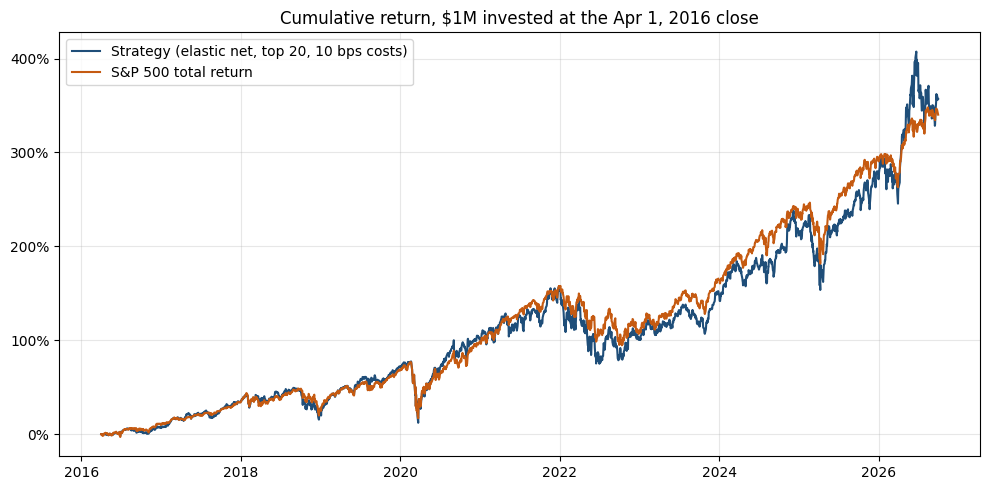

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(hist.index, hist.nav / 1e6 - 1, label=f"Strategy (elastic net, top {TOP_N}, 10 bps costs)", color="#1f4e79")
ax.plot(sp.index, sp / 1e6 - 1, label="S&P 500 total return", color="#c55a11")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set_title("Cumulative return, $1M invested at the Apr 1, 2016 close")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("cumulative_return.png", dpi=150)
plt.show()

### Sensitivity: costs and missing prices
Same scores, one assumption changed each time. "write_off" values a stock at 0 after 5 sessions
without a quote (the database has no delisting proceeds, so the truth is between the two).

In [14]:
# same scores, we change one thing at a time
runs = {"base: 10 bps, freeze": final}
for cost in [0, 25, 50]:
    runs[f"{cost} bps"] = bt.run_backtest(prices, test_scores, "2016-04-01", "2026-09-30", top_n=TOP_N, cost_bps=cost)
runs["10 bps, write_off"] = bt.run_backtest(prices, test_scores, "2016-04-01", "2026-09-30", top_n=TOP_N,
                                            missing_policy="write_off")
display(pd.DataFrame({k: pd.concat([bt.performance(r["history"].nav), bt.trading_stats(r)]) for k, r in runs.items()}).T
        [["final_value", "CAGR", "max_drawdown", "Sharpe", "annual_turnover", "annual_cost_drag", "average_cash_share"]].round(4))

# lots still open at the end with no recent price: the "frozen" stocks
lots = final["open_lots"]
frozen =lots[lots.last_quote < hist.index[-1] - pd.Timedelta(days=10)]
print(f"open lots at the end: {len(lots)}, of which {len(frozen)} without a quote for 10+ days "
      f"(value {frozen.value.sum():,.0f} USD, {frozen.value.sum() / hist.nav.iloc[-1]:.1%} of the portfolio)")
display(final["events"].event.str.replace(r"\(.*\)", "", regex=True).value_counts().to_frame())

,final_value,CAGR,max_drawdown,Sharpe,annual_turnover,annual_cost_drag,average_cash_share
"base: 10 bps, freeze","4,571,115.1959",0.1557,-0.3683,0.6601,7.5263,0.0075,0.0231
0 bps,"4,958,358.1418",0.1647,-0.3679,0.6935,7.5284,0.0000,0.0231
25 bps,"4,046,721.6725",0.1424,-0.3687,0.6099,7.5229,0.0188,0.0231
50 bps,"3,304,325.3832",0.1206,-0.3695,0.5261,7.5168,0.0376,0.0231
"10 bps, write_off","3,858,666.1116",0.1372,-0.3722,0.5699,7.9905,0.0080,0.0239


open lots at the end: 380, of which 60 without a quote for 10+ days (value 691,440 USD, 15.1% of the portfolio)


,count
event,
no quote for more than 5 sessions: mark frozen,60
exit delayed: no quote on due date,60
order skipped: no quote,23
bad print ignored,3


### Risk taken

In [15]:
# beta, correlation and tracking error vs the S&P, with daily returns
daily = pd.DataFrame({"strategy": hist.nav, "sp": sp}).pct_change().dropna()
print(f"beta: {daily.cov().iloc[0, 1] / daily.sp.var():.2f}, correlation: {daily.corr().iloc[0, 1]:.2f}, "
      f"tracking error: {(daily.strategy - daily.sp).std() * np.sqrt(252):.1%}")
# return of each calendar year
yearly = pd.DataFrame({"Strategy": hist.nav, "S&P 500 TR": sp}).resample("YE").last()
yearly = pd.concat([pd.DataFrame({"Strategy": [1e6], "S&P 500 TR": [1e6]}, index=[hist.index[0]]), yearly])
display((yearly.pct_change().dropna() * 100).round(1).rename(index=lambda d: d.year).T)
buys = final["trades"][final["trades"].side == "BUY"].merge(panel[["date", "symbol", "sector"]],
                                                           left_on=["signal_date", "symbol"], right_on=["date", "symbol"])
print("money invested by sector:")
display((buys.groupby("sector").value.sum() / buys.value.sum()).sort_values(ascending=False).round(3).to_frame().T)

beta: 1.14, correlation: 0.89, tracking error: 10.9%


,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Strategy,6.6000,26.0000,-7.7000,38.3000,17.7000,25.5000,-20.3000,24.5000,24.0000,19.2000,23.0000
S&P 500 TR,9.8000,21.8000,-4.4000,31.5000,18.4000,28.7000,-18.1000,26.3000,25.0000,17.9000,12.7000


money invested by sector:


sector,Technology,Consumer Cyclical,Industrials,Financial Services,Healthcare,Consumer Defensive,Basic Materials,Communication Services,Real Estate,Energy,Utilities
value,0.2920,0.2040,0.1610,0.1040,0.0930,0.0570,0.0380,0.0210,0.0210,0.0070,0.0030


### Where does the result come from?
Not used for any decision: the out-of-sample rank IC, and the same backtester buying **every**
eligible stock (no model). Strategy vs S&P = (equal-weight universe vs S&P) + (model vs universe).

In [16]:
# out-of-sample rank IC: does the score still rank the stocks well in the test?
test_ic, test_ic_by_date = model.ranking_metrics(test_scores, panel[panel.label_end <= "2026-09-30"], top_n=TOP_N)
display(test_ic.round(4).to_frame("test").T)
print("rank IC by entry year:")
display(test_ic_by_date.ic.groupby((test_ic_by_date.index + pd.offsets.MonthBegin(1)).year).mean().round(3).to_frame().T)
# same backtester, but we buy all the stocks (score = 0 for everyone, so no model)
universe = bt.run_backtest(prices, test_scores.assign(score=0.0), "2016-04-01", "2026-09-30", top_n=1000)
display(pd.DataFrame({"Strategy": bt.performance(hist.nav), "Equal-weight universe (no model)": bt.performance(universe["history"].nav),
                      "S&P 500 TR": bt.performance(sp)}).T.round(4))

,mean_rank_IC,IC_t_stat,share_IC_positive,top20_minus_all_90d,dates
test,0.0359,3.5556,0.6613,0.0166,124.0000


rank IC by entry year:


date,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
ic,-0.0220,0.1220,0.0260,0.0620,0.0170,0.0470,-0.0150,0.1060,-0.0090,0.0130,0.0330


,final_value,total_return,CAGR,max_drawdown,volatility,Sharpe
Strategy,"4,571,115.1959",3.5711,0.1557,-0.3683,0.2299,0.6601
Equal-weight universe (no model),"2,267,062.9922",1.2671,0.0811,-0.3949,0.1813,0.4129
S&P 500 TR,"4,402,746.7763",3.4027,0.1516,-0.3379,0.1782,0.7725


### What the model learned
Coefficients at each quarterly refit of the test. A characteristic goes from rank -0.5 to +0.5, so a
coefficient of 0.01 means: the highest-ranked stock on it is predicted to beat the lowest-ranked one
by 1% over 90 days. `log_size_rank` high = smaller company; `drawdown_252` high = close to the 1-year high.

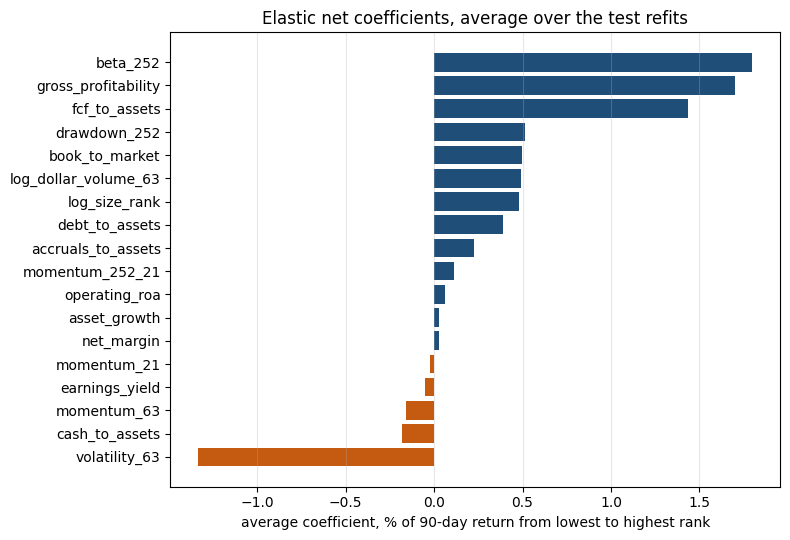

,average,share of refits not 0,share of refits > 0
beta_252,0.0180,1.0000,1.0000
gross_profitability,0.0170,1.0000,1.0000
fcf_to_assets,0.0144,1.0000,1.0000
drawdown_252,0.0052,1.0000,1.0000
book_to_market,0.0050,0.9048,0.9048
log_dollar_volume_63,0.0049,0.5952,0.5952
log_size_rank,0.0048,0.9762,0.9762
debt_to_assets,0.0039,1.0000,1.0000
accruals_to_assets,0.0022,0.9048,0.9048
momentum_252_21,0.0012,0.5000,0.5000


In [17]:
# coefficients of each quarterly refit, then the average
coefs = pd.DataFrame({d: m.coef_ for d, m in test_models.items()}, index=data.FEATURES).T
table = pd.DataFrame({"average": coefs.mean(), "share of refits not 0": (coefs != 0).mean(),
                      "share of refits > 0": (coefs > 0).mean()}).sort_values("average")
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(table.index, table.average * 100, color=np.where(table.average > 0, "#1f4e79", "#c55a11"))
ax.set_xlabel("average coefficient, % of 90-day return from lowest to highest rank")
ax.set_title("Elastic net coefficients, average over the test refits")
ax.grid(alpha=0.3, axis="x")
fig.tight_layout()
plt.show()
display(table.iloc[::-1].round(4))